In [1]:
# Cell 1 — Derive Chebyshev g-values from first principles (no hardcoding)

import numpy as np
def chebyshev_g_values(n, ripple_dB):
    epsilon = np.sqrt(10**(ripple_dB/10) - 1)
    beta = np.log(1.0 / np.tanh(ripple_dB / 17.37))
    gamma = np.sinh(beta / (2*n))

    g = np.zeros(n+1)
    g[0] = 1.0

    # g1
    a1 = np.sin(np.pi / (2*n))
    g[1] = 2.0 * a1 / gamma

    # g2 to gn
    for k in range(2, n+1):
        a_k = np.sin((2*k - 1) * np.pi / (2*n))
        b_k = np.sin((2*k - 3) * np.pi / (2*n))
        g[k] = (4.0 * a_k * b_k) / (g[k-1] * (gamma**2 + np.sin((k-1)*np.pi/n)**2))

    return g

n_poles = 5
ripple_dB = 0.1
g = chebyshev_g_values(n_poles, ripple_dB)
print("=== Derived Chebyshev g-values ===")
for i, gi in enumerate(g):
    print(f"  g{i} = {gi:.4f}")

# Verify against standard 0.1 dB, n=5 table
print("Standard table: g1=1.1468, g2=1.3712, g3=1.9750, g4=1.3712, g5=1.1468")

=== Derived Chebyshev g-values ===
  g0 = 1.0000
  g1 = 1.1468
  g2 = 1.3712
  g3 = 1.9750
  g4 = 1.3712
  g5 = 1.1468
Standard table: g1=1.1468, g2=1.3712, g3=1.9750, g4=1.3712, g5=1.1468


In [2]:
# Cell 2 — WB2CBA 5-pole Chebyshev LPF (50 Ω), fc = 15 MHz

R = 50.0
fc = 15.0e6
f0 = 14.0e6
w0 = 2*np.pi*f0

C1 = g[1] / (2*np.pi*fc*R)
L2 = g[2] * R / (2*np.pi*fc)
C3 = g[3] / (2*np.pi*fc*R)
L4 = g[4] * R / (2*np.pi*fc)
C5 = g[5] / (2*np.pi*fc*R)

print("\n=== WB2CBA LPF Component Values ===")
print(f"  C1 = {C1*1e12:.1f} pF")
print(f"  L2 = {L2*1e9:.1f} nH")
print(f"  C3 = {C3*1e12:.1f} pF")
print(f"  L4 = {L4*1e9:.1f} nH")
print(f"  C5 = {C5*1e12:.1f} pF")

# ABCD matrices and S-parameters
def abcd_shunt_c(C, w):
    return np.array([[1, 0], [1j*w*C, 1]], dtype=complex)

def abcd_series_l(L, w):
    return np.array([[1, 1j*w*L], [0, 1]], dtype=complex)

def s_params(abcd, R_in, R_out):
    A, B = abcd[0,0], abcd[0,1]
    C, D = abcd[1,0], abcd[1,1]
    denom = A + B/R_out + C*R_in + D*R_in/R_out
    S11 = (A + B/R_out - C*R_in - D*R_in/R_out) / denom
    S21 = 2.0 * np.sqrt(R_in/R_out) / denom
    return S11, S21

def wb2cba_lpf(w):
    abcd = (abcd_shunt_c(C1, w)
            @ abcd_series_l(L2, w)
            @ abcd_shunt_c(C3, w)
            @ abcd_series_l(L4, w)
            @ abcd_shunt_c(C5, w))
    return s_params(abcd, R, R)

# Sweep
w_rad = np.linspace(2*np.pi*0.1e6, 2*np.pi*5*f0, 5000)
f_hz = w_rad / (2*np.pi)
S11, S21 = zip(*[wb2cba_lpf(w) for w in w_rad])
S11_dB = 20*np.log10(np.maximum(np.abs(S11), 1e-30))
S21_dB = 20*np.log10(np.maximum(np.abs(S21), 1e-30))

i_f0  = np.argmin(np.abs(f_hz - f0))
i_2f0 = np.argmin(np.abs(f_hz - 2*f0))
i_3f0 = np.argmin(np.abs(f_hz - 3*f0))

print("\n=== WB2CBA LPF Performance ===")
print(f"  S11(f0)  = {S11_dB[i_f0]:6.1f} dB")
print(f"  S21(f0)  = {S21_dB[i_f0]:6.3f} dB")
print(f"  S21(2f0) = {S21_dB[i_2f0]-S21_dB[i_f0]:6.1f} dBc  (FCC requires ≤ −43)")
print(f"  S21(3f0) = {S21_dB[i_3f0]-S21_dB[i_f0]:6.1f} dBc")


=== WB2CBA LPF Component Values ===
  C1 = 243.4 pF
  L2 = 727.4 nH
  C3 = 419.1 pF
  L4 = 727.4 nH
  C5 = 243.4 pF

=== WB2CBA LPF Performance ===
  S11(f0)  =  -27.9 dB
  S21(f0)  = -0.007 dB
  S21(2f0) =  -31.3 dBc  (FCC requires ≤ −43)
  S21(3f0) =  -51.0 dBc


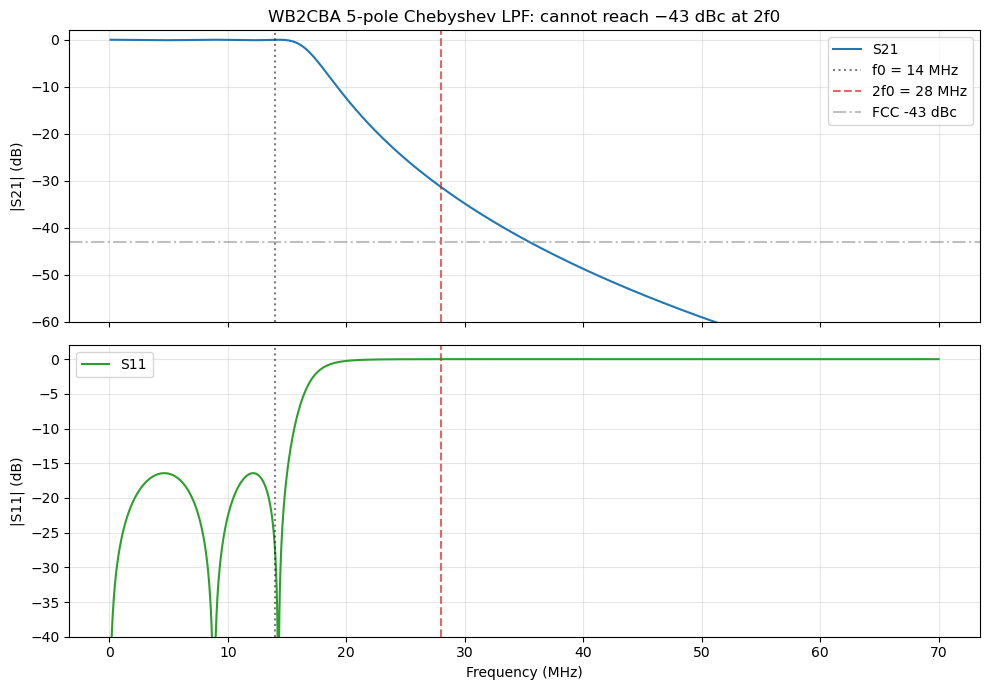

In [3]:
# Cell 3 — Plot S11 and S21 for the WB2CBA LPF

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax[0].plot(f_hz/1e6, S21_dB, 'C0', lw=1.5, label='S21')
ax[0].axvline(f0/1e6, color='k', ls=':', alpha=0.5, label='f0 = 14 MHz')
ax[0].axvline(2*f0/1e6, color='C3', ls='--', alpha=0.7, label='2f0 = 28 MHz')
ax[0].axhline(-43, color='gray', ls='-.', alpha=0.5, label='FCC -43 dBc')
ax[0].set_ylabel('|S21| (dB)')
ax[0].set_title('WB2CBA 5-pole Chebyshev LPF: cannot reach −43 dBc at 2f0')
ax[0].legend()
ax[0].grid(alpha=0.3)
ax[0].set_ylim(-60, 2)

ax[1].plot(f_hz/1e6, S11_dB, 'C2', lw=1.5, label='S11')
ax[1].axvline(f0/1e6, color='k', ls=':', alpha=0.5)
ax[1].axvline(2*f0/1e6, color='C3', ls='--', alpha=0.7)
ax[1].set_xlabel('Frequency (MHz)')
ax[1].set_ylabel('|S11| (dB)')
ax[1].legend()
ax[1].grid(alpha=0.3)
ax[1].set_ylim(-40, 2)

plt.tight_layout()
plt.show()